In [86]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
)
import joblib

In [87]:
df = pd.read_csv("bhdacf26.csv")

print("Rows and columns:", df.shape)
print("First five rows:")
display(df.head())

print("\nAccount-level default rate:", round(df["bad_flg_90plus_24m"].mean() * 100, 2), "%")
print("Consumer-level default rate:", round(df["consumer_bad_flg_90plus_24m"].mean() * 100, 2), "%")

# Count how many accounts actually defaulted.
print("\nTarget class counts:")
print(df["bad_flg_90plus_24m"].value_counts().sort_index())

Rows and columns: (77077, 40)
First five rows:


,Acct1,Acct2,Acct3,Acct4,Acct5,Acct6,Acct7,Acct9,Acct10,Acct15,...,Inq1,line_12m,line_24m,Repo1,Score1,Score2,Util1,Util2,Util3,Util4
0,83,3,19,0,205,17,96,0,0,0,...,1,19500,19500,0,654,668,73,56,89,9
1,84,9,15,2,123,12,68,0,0,0,...,3,1000,1000,0,627,626,75,76,81,12
2,84,9,16,0,204,25,82,0,2,0,...,5,11000,11000,0,730,722,34,93,17,11
3,84,5,10,0,205,8,94,0,1,0,...,1,500,500,0,643,657,81,98,88,11
4,59,1,12,0,194,7,97,0,1,1,...,0,1900,3200,0,817,762,78,94,0,12



Account-level default rate: 7.4 %
Consumer-level default rate: 11.54 %

Target class counts:
bad_flg_90plus_24m
0    71377
1     5700
Name: count, dtype: int64


In [88]:
features = [
    "Acct1", "Acct2", "Acct3", "Acct4", "Acct5", "Acct6", "Acct7",
    "BK1", "BK2", "BK3", "CO1", "CO2", "CO3", "Col1",
    "Del1", "Del2", "Del3", "Del4", "Del5", "Del6", "Del8", "Del9",
    "Inq1", "Repo1", "Score1", "Score2", "Util1", "Util2", "Util3"
]
target = "bad_flg_90plus_24m"

X = df[features]   # All 29 predictor columns
Y = df[target]     # One outcome column (0 or 1)

print("Number of features:", X.shape[1])
print("Number of missing feature values:", X.isna().sum().sum())

# This file has no pandas NaNs in the 29 predictors. If you change data,
# investigate missing values and special sentinel codes before training.
if X.isna().any().any():
    raise ValueError("Missing feature values found; investigate before training.")

Number of features: 29
Number of missing feature values: 0


In [89]:
# First: separate out 60% for training and 40% for later.
X_train, X_other, Y_train, Y_other = train_test_split(
    X, Y, test_size=0.40, random_state=42, stratify=Y
)

# Second: split the remaining 40% into 20% validation + 20% test.
X_val, X_test, Y_val, Y_test = train_test_split(
    X_other, Y_other, test_size=0.50, random_state=42, stratify=Y_other
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Testing rows:", len(X_test))

Training rows: 46246
Validation rows: 15415
Testing rows: 15416


In [90]:
model = RandomForestClassifier(
    n_estimators=200, #200 trees
    max_depth=10, #max depth of 10 splits
    min_samples_leaf=20, # Each terminal leaf must contain >=20 training rows
    max_features="sqrt", # At each split, consider about sqrt(29) features
    class_weight="balanced_subsample", # Emphasize rarer defaults in each bootstrap sample
    random_state=42, # Reproducible results
    n_jobs=-1  # Use available CPU cores to train faster
)

model.fit(X_train, Y_train)
print("Random forest trained!")

Random forest trained!


In [91]:
validation_scores = model.predict_proba(X_val)[:, 1]

thresholds_to_try = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]
results = []

for cutoff in thresholds_to_try:
    validation_predictions = (validation_scores >= cutoff).astype(int)
    f1 = f1_score(Y_val, validation_predictions)
    results.append({"Threshold": cutoff, "F1 score": f1})

threshold_results = pd.DataFrame(results)
display(threshold_results)

best_row = threshold_results.loc[threshold_results["F1 score"].idxmax()]
best_threshold = float(best_row["Threshold"])
print("Selected threshold:", best_threshold)

,Threshold,F1 score
0,0.30,0.255775
1,0.35,0.271481
2,0.40,0.291457
3,0.45,0.308710
4,0.50,0.327327
5,0.55,0.344944
6,0.60,0.362287
7,0.65,0.371401
8,0.70,0.370487


Selected threshold: 0.65


In [92]:
# Get model scores for the test accounts.
test_scores = model.predict_proba(X_test)[:, 1]

# Convert scores to 0/1 predictions using our chosen threshold.
Y_pred = (test_scores >= best_threshold).astype(int)

print("Accuracy:", round(accuracy_score(Y_test, Y_pred), 3))
print("Precision:", round(precision_score(Y_test, Y_pred), 3))
print("Recall:", round(recall_score(Y_test, Y_pred), 3))
print("F1 score:", round(f1_score(Y_test, Y_pred), 3))
print("ROC-AUC:", round(roc_auc_score(Y_test, test_scores), 3))
print("Average precision:", round(average_precision_score(Y_test, test_scores), 3))

print("\nClassification report:")
print(classification_report(Y_test, Y_pred, target_names=["No default", "Default"]))

Accuracy: 0.874
Precision: 0.294
Recall: 0.5
F1 score: 0.37
ROC-AUC: 0.827
Average precision: 0.309

Classification report:
              precision    recall  f1-score   support

  No default       0.96      0.90      0.93     14276
     Default       0.29      0.50      0.37      1140

    accuracy                           0.87     15416
   macro avg       0.63      0.70      0.65     15416
weighted avg       0.91      0.87      0.89     15416



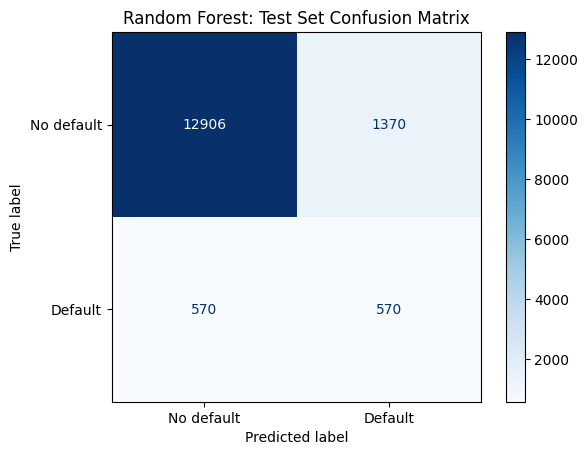

In [93]:
ConfusionMatrixDisplay.from_predictions(
    Y_test,
    Y_pred,
    display_labels=["No default", "Default"],
    cmap="Blues",
    values_format="d"
)
plt.title("Random Forest: Test Set Confusion Matrix")
plt.show()

Top 12 predictors:
Score1    0.252352
Score2    0.213942
Acct7     0.081316
Util3     0.079661
Acct1     0.054042
Acct5     0.043195
Col1      0.027053
Del1      0.025729
Util1     0.024982
Del6      0.024808
Inq1      0.024555
Del4      0.024149
dtype: float64


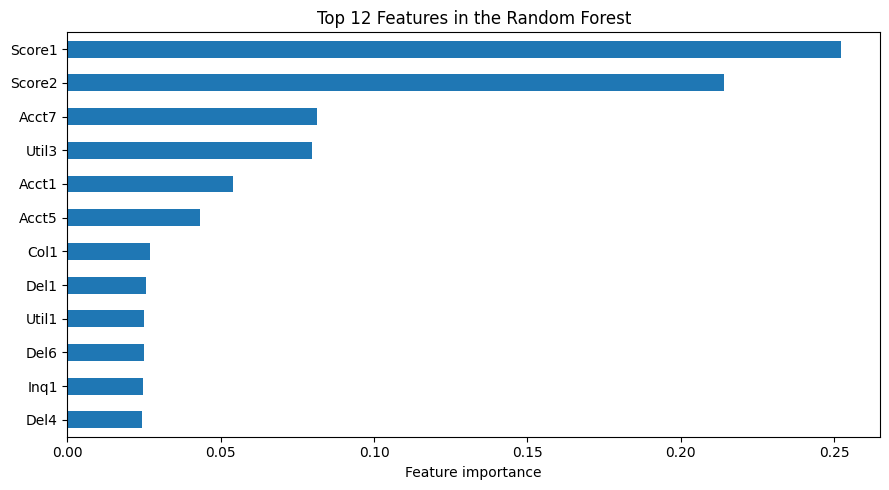

In [94]:
importance = pd.Series(model.feature_importances_, index=features)
important_features = importance.sort_values(ascending=False).head(12)

print("Top 12 predictors:")
print(important_features)

important_features.sort_values().plot(kind="barh", figsize=(9, 5))
plt.xlabel("Feature importance")
plt.title("Top 12 Features in the Random Forest")
plt.tight_layout()
plt.show()

In [95]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

folds = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    model,
    X_train,
    Y_train,
    cv=folds,
    scoring="roc_auc",
    n_jobs=1
)

print(cv_scores)
print("Average:", cv_scores.mean())

[0.82205097 0.80941322 0.83534666 0.84905931 0.82094748]
Average: 0.8273635295670712


In [96]:
train_probs = model.predict_proba(X_train)[:, 1]
val_probs = model.predict_proba(X_val)[:, 1]

train_auc = roc_auc_score(Y_train, train_probs)
val_auc = roc_auc_score(Y_val, val_probs)

print("Training ROC-AUC:", train_auc)
print("Validation ROC-AUC:", val_auc)

Training ROC-AUC: 0.8934077730012074
Validation ROC-AUC: 0.8238745813746274
